# Supervised machine learning lifecycle
**MCAIPAT Laboratory 02 — Google Colab**  
**Cyrus Gabilla**

## Prediction problem
Given a secondary-school student's background, study habits, and social factors, predict whether the student is **at risk of failing** Portuguese class (`AtRisk = 1`) or not (`AtRisk = 0`).

## Dataset
| Item | Detail |
|---|---|
| Title | Student Performance (Portuguese language course) |
| Source | UCI Machine Learning Repository, dataset 320 |
| Authors | Paulo Cortez and Alice Silva (University of Minho) |
| URL | https://archive.ics.uci.edu/dataset/320/student+performance |
| License / use | Public research dataset; cite Cortez & Silva (2008) |
| File | `student_performance.csv` |
| Why this dataset | Matches the lab's Education example, requires uploading a CSV, mixes categorical and numeric features, and requires uploading a CSV with mixed feature types. |



## Lifecycle covered in this notebook
1. Identify and load a public CSV  
2. Explore the data (EDA)  
3. Preprocess (encode, scale, split)  
4. Train at least three supervised classifiers  
5. Evaluate and compare with metrics beyond accuracy  
6. Predict new students and interpret the result  



## 0. Imports — what each library does

| Import | Why it is here |
|---|---|
| `pandas` | Load the CSV into a table; compute counts, missing values, and summaries. |
| `numpy` | Numeric helpers for the sample students at the end. |
| `matplotlib.pyplot` | Base plotting library. |
| `seaborn` | Clearer statistical charts: bars, boxes, histograms, scatter plots, heatmaps. |
| `train_test_split` | Hold out 20% of students so we score on students the model did not see while training. |
| `ColumnTransformer` + `Pipeline` | Keep encoding and scaling inside the model so those steps are fit on the training rows only. |
| `OneHotEncoder` | Turn text categories (school, sex, job, yes/no flags) into numeric columns. |
| `StandardScaler` | rescales each numeric feature so they share a comparable scale: roughly mean 0 and standard deviation 1. |
| `SVC` + `CalibratedClassifierCV` | Support Vector Machine with probability calibration — finds a wide margin between at-risk and not-at-risk students. |
| `GaussianNB` | Naive Bayes — estimates how likely the feature pattern is for at-risk vs pass students. |
| `GradientBoostingClassifier` | Builds many small trees in sequence; each tree corrects earlier mistakes. |
| Metric helpers | Accuracy, precision, recall, F1, and the confusion matrix. |

The three algorithms are **SVM**, **Naive Bayes**, and **Gradient Boosting**. These three algorithms are appropriate for binary classification with mixed feature types.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)

sns.set_theme(style="whitegrid")
print("Libraries loaded.")
print("Problem: predict AtRisk students in Portuguese class")
print("Lifecycle: load -> explore -> preprocess -> train -> evaluate -> predict")


Libraries loaded.
Problem: predict AtRisk students in Portuguese class
Lifecycle: load -> explore -> preprocess -> train -> evaluate -> predict


## 1. Dataset identification and loading

### What the columns mean (short guide)
The original UCI file has 33 attributes. Important ones for this lab:

- **Background:** `school`, `sex`, `age`, `address`, `famsize`, `Pstatus`, `Medu`, `Fedu`, `Mjob`, `Fjob`, `guardian`
- **School behavior:** `traveltime`, `studytime`, `failures`, `schoolsup`, `famsup`, `paid`, `activities`, `nursery`, `higher`, `internet`, `absences`
- **Social / health:** `romantic`, `famrel`, `freetime`, `goout`, `Dalc`, `Walc`, `health`
- **Grades:** `G1` (period 1), `G2` (period 2), `G3` (final grade, 0–20)

### Target we will create
UCI recommends being careful with `G1` and `G2` because they are almost the final grade. Predicting `G3` with period grades is easy but less useful. This notebook:

1. Creates `AtRisk = 1` when final grade `G3 < 10` (fail), else `0` (pass).
2. **Drops** `G1`, `G2`, and `G3` from the features so the model must use background and behavior only.

That matches a realistic early-warning use case: flag students who may fail before final grades are known.


In [2]:
candidates = [
    Path("/content/student_performance.csv"),
    Path("student_performance.csv"),
    Path("/home/cyrus/Documents/Dev/data-requests/APC-MSCS/MCAIPAT/Laboratory/laboratory02/student_performance.csv"),
]
csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError(
        "Upload student_performance.csv to Colab (Files panel), "
        "or keep it next to this notebook on your computer."
    )

df_raw = pd.read_csv(csv_path)
print("Source file:", csv_path)
print("Records (rows):", df_raw.shape[0])
print("Attributes (columns):", df_raw.shape[1])
print("Column names:")
print(df_raw.columns.tolist())
print("\nFirst five records:")
display(df_raw.head())
print("\nData types and non-null counts:")
print(df_raw.info())
print("\nMissing values per column:")
print(df_raw.isnull().sum())
print("Total missing cells:", int(df_raw.isnull().sum().sum()))
print("Duplicate rows:", int(df_raw.duplicated().sum()))


Source file: /content/student_performance.csv
Records (rows): 649
Attributes (columns): 33
Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

First five records:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13



Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery     649 n

## 2. Define features and target

`AtRisk` is the dependent variable (what we predict). Everything else that remains after dropping the period and final grades is an independent variable (feature).

Why drop `G1`/`G2`/`G3` from `X`:
- `G3` is used only to build the label.
- `G1` and `G2` are earlier grades of the same course. Including them would leak almost the answer and would not show a meaningful early-warning model.


In [3]:
df = df_raw.copy()
df["AtRisk"] = (df["G3"] < 10).astype(int)

feature_cols = [c for c in df.columns if c not in ["G1", "G2", "G3", "AtRisk"]]
print("Target variable: AtRisk  (1 = fail / at risk, 0 = pass)")
print(df["AtRisk"].value_counts().rename({0: "Pass (0)", 1: "At risk / fail (1)"}))
print("At-risk rate:", round(df["AtRisk"].mean(), 4))
print("\nIndependent variables (features):", len(feature_cols))
print(feature_cols)
print("\nFeature preview with target:")
display(df[feature_cols + ["AtRisk"]].head())


Target variable: AtRisk  (1 = fail / at risk, 0 = pass)
AtRisk
Pass (0)              549
At risk / fail (1)    100
Name: count, dtype: int64
At-risk rate: 0.1541

Independent variables (features): 30
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Feature preview with target:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,AtRisk
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,no,no,4,3,4,1,1,3,4,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,yes,no,5,3,3,1,1,3,2,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,yes,no,4,3,2,2,3,3,6,0
3,GP,F,15,U,GT3,T,4,2,health,services,...,yes,yes,3,2,2,1,1,5,0,0
4,GP,F,16,U,GT3,T,3,3,other,other,...,no,no,4,3,2,1,2,5,0,0


## 3. Exploratory data analysis (EDA)

Before training, we look for class imbalance, relationships, and odd values.

**What to notice while you read the charts**
- Most students pass, so a lazy model that always says "pass" would look accurate and still miss every failing student. That is why the lab asks for precision, recall, and F1, not accuracy alone.
- Past `failures` and wanting higher education (`higher`) are usually strong signals.
- Charts required by the lab: bar, histogram, box plot, scatter plot, and correlation heatmap.


Descriptive statistics for numeric columns


,count,mean,std,min,25%,50%,75%,max
age,649.0,16.744,1.218,15.0,16.0,17.0,18.0,22.0
Medu,649.0,2.515,1.135,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,2.307,1.100,0.0,1.0,2.0,3.0,4.0
traveltime,649.0,1.569,0.749,1.0,1.0,1.0,2.0,4.0
studytime,649.0,1.931,0.830,1.0,1.0,2.0,2.0,4.0
failures,649.0,0.222,0.593,0.0,0.0,0.0,0.0,3.0
famrel,649.0,3.931,0.956,1.0,4.0,4.0,5.0,5.0
freetime,649.0,3.180,1.051,1.0,3.0,3.0,4.0,5.0
goout,649.0,3.185,1.176,1.0,2.0,3.0,4.0,5.0
Dalc,649.0,1.502,0.925,1.0,1.0,1.0,2.0,5.0



Class balance
AtRisk
Pass       0.8459
At risk    0.1541
Name: proportion, dtype: float64


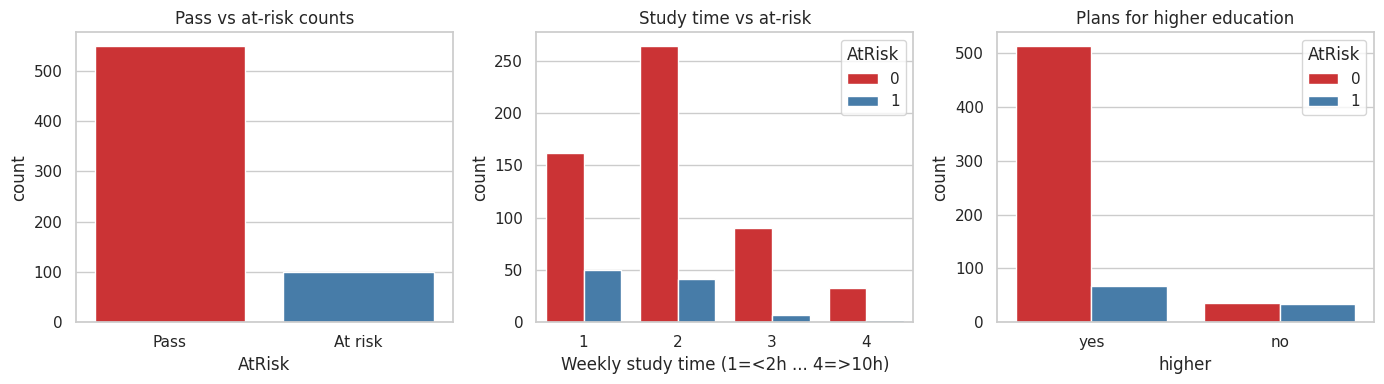

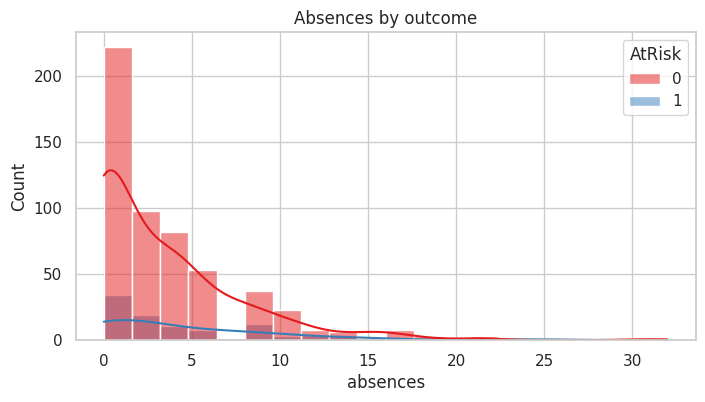

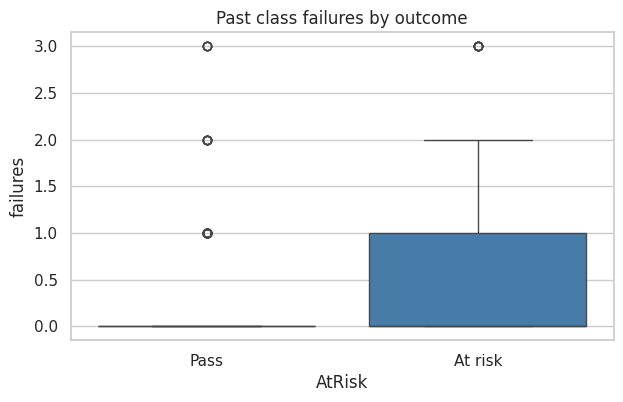

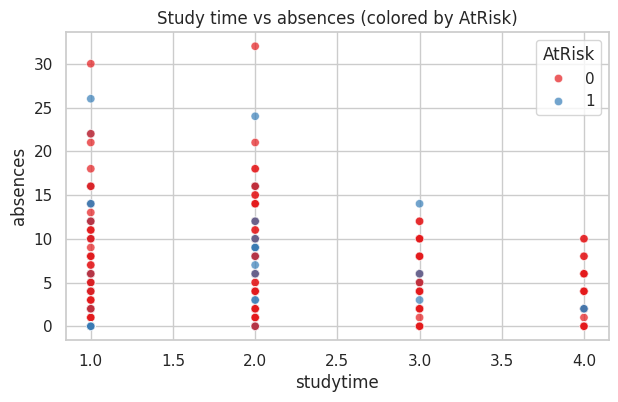

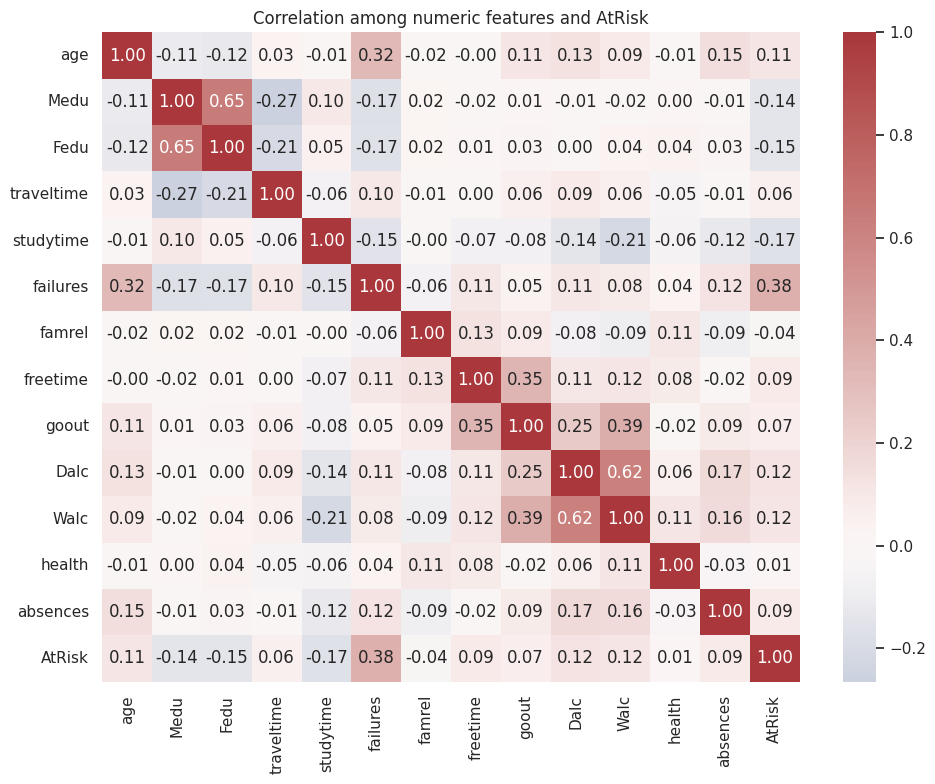

EDA observation: AtRisk correlates most strongly with past failures.
Correlation of failures with AtRisk: 0.38


In [4]:
print("Descriptive statistics for numeric columns")
display(df.describe().T.round(3))

print("\nClass balance")
print(df["AtRisk"].value_counts(normalize=True).rename({0: "Pass", 1: "At risk"}).round(4))

# Bar charts
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.countplot(data=df, x="AtRisk", hue="AtRisk", ax=axes[0], palette="Set1", legend=False)
axes[0].set_title("Pass vs at-risk counts")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Pass", "At risk"])

sns.countplot(data=df, x="studytime", hue="AtRisk", ax=axes[1], palette="Set1")
axes[1].set_title("Study time vs at-risk")
axes[1].set_xlabel("Weekly study time (1=<2h ... 4=>10h)")

sns.countplot(data=df, x="higher", hue="AtRisk", ax=axes[2], palette="Set1")
axes[2].set_title("Plans for higher education")
fig.tight_layout()
plt.show()

# Histogram
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="absences", hue="AtRisk", bins=20, kde=True, palette="Set1")
plt.title("Absences by outcome")
plt.show()

# Box plot
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="AtRisk", y="failures", hue="AtRisk", palette="Set1", legend=False)
plt.xticks([0, 1], ["Pass", "At risk"])
plt.title("Past class failures by outcome")
plt.show()

# Scatter plot
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x="studytime", y="absences", hue="AtRisk", palette="Set1", alpha=0.7)
plt.title("Study time vs absences (colored by AtRisk)")
plt.show()

# Correlation heatmap for numeric predictors + target
numeric_for_corr = [
    "age", "Medu", "Fedu", "traveltime", "studytime", "failures",
    "famrel", "freetime", "goout", "Dalc", "Walc", "health", "absences", "AtRisk"
]
plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_for_corr].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation among numeric features and AtRisk")
plt.tight_layout()
plt.show()

print("EDA observation: AtRisk correlates most strongly with past failures.")
print("Correlation of failures with AtRisk:", round(df[["failures", "AtRisk"]].corr().iloc[0, 1], 3))


## 4. Data preprocessing

### What we do and why
1. **No missing-value fill is required** for this file: UCI reports a complete table. We still check and report that fact.
2. **No duplicate removal** is needed after the check in Section 1.
3. **Categorical encoding:** columns such as `sex`, `Mjob`, and `internet` are text. Models need numbers, so `OneHotEncoder` creates 0/1 columns.
4. **Scaling:** `StandardScaler` centers and scales numeric columns. SVM and KNN use distances or margins; without scaling, `absences` would dominate `studytime`.
5. **Separate X and y.**
6. **80% train / 20% test**, `random_state=42`, `stratify=y` so the rare at-risk class appears in both parts.

Encoding and scaling sit inside a `Pipeline`. That prevents information from the test students from leaking into the scaler or encoder.


In [5]:
X = df[feature_cols].copy()
y = df["AtRisk"].copy()

categorical_features = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
numeric_features = [c for c in X.columns if c not in categorical_features]
print("Categorical features (", len(categorical_features), "):", categorical_features)
print("Numeric features (", len(numeric_features), "):", numeric_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("\nTraining students:", len(X_train))
print("Testing students:", len(X_test))
print("Train at-risk rate:", round(y_train.mean(), 4))
print("Test at-risk rate:", round(y_test.mean(), 4))

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)
print("\nPreprocessor ready: StandardScaler for numbers, OneHotEncoder for categories.")
print("It will fit only when a model is trained on X_train.")


Categorical features ( 17 ): ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Numeric features ( 13 ): ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Training students: 519
Testing students: 130
Train at-risk rate: 0.1541
Test at-risk rate: 0.1538

Preprocessor ready: StandardScaler for numbers, OneHotEncoder for categories.
It will fit only when a model is trained on X_train.


## 5. Model development — three supervised classifiers

| Algorithm | Purpose in plain words | Key settings |
|---|---|---|
| Support Vector Machine (`SVC`) | Draws a boundary that separates at-risk from not-at-risk with a wide margin. | Balanced class weights; wrapped in `CalibratedClassifierCV` so we can report risk probabilities. |
| Naive Bayes (`GaussianNB`) | Estimates the chance a feature pattern belongs to an at-risk student. | Works from the encoded numeric matrix after preprocessing. |
| Gradient Boosting | Builds many small trees one after another; each tree focuses on previous mistakes. | 150 trees, depth 3, learning rate 0.05, trained with balanced sample weights. |

Training steps for every model:
1. Fit the preprocessor on `X_train`.
2. Fit the classifier on the transformed training data.
3. Predict labels for `X_test`.


In [6]:
from sklearn.utils.class_weight import compute_sample_weight

# Only about 15% of students are at risk. Without balancing, some models
# learn to always predict "Pass" and look accurate while catching nobody.
models = {
    "Support Vector Machine": CalibratedClassifierCV(
        SVC(kernel="rbf", class_weight="balanced", random_state=42),
        ensemble=False,
    ),
    "Naive Bayes": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42
    ),
}

trained = {}
for name, algorithm in models.items():
    pipe = Pipeline([
        ("preprocess", preprocessor),
        ("model", algorithm),
    ])
    if name == "Gradient Boosting":
        sample_weight = compute_sample_weight(class_weight="balanced", y=y_train)
        pipe.fit(X_train, y_train, model__sample_weight=sample_weight)
    else:
        pipe.fit(X_train, y_train)
    trained[name] = pipe
    print("Trained:", name)
print("\nBalancing note: SVM uses class_weight='balanced' and probability calibration.")
print("Gradient Boosting uses balanced sample weights.")
print("All models are fitted on the same training students.")


Trained: Support Vector Machine
Trained: Naive Bayes
Trained: Gradient Boosting

Balancing note: SVM uses class_weight='balanced' and probability calibration.
Gradient Boosting uses balanced sample weights.
All models are fitted on the same training students.


## 6. Evaluation and comparison

### How to read the metrics for this problem
| Metric | Meaning here |
|---|---|
| Accuracy | Share of test students labeled correctly. Looks high if the model mostly predicts "pass". |
| Precision | Of students predicted at-risk, how many really failed. High precision means fewer false alarms. |
| Recall | Of students who really failed, how many we caught. High recall means fewer missed failing students. |
| F1 | Balance of precision and recall for the at-risk class. |
| Confusion matrix | Rows = true class; columns = predicted class. Order: Pass, At risk. |

We rank models by **F1 of the at-risk class**, not by accuracy alone. An early-warning tool that misses failing students is weak even if accuracy looks good.


Comparison sorted by F1 of the at-risk class


,Algorithm,Accuracy,Precision,Recall,F1
0,Naive Bayes,80.0%,40.62%,65.0%,50.0%
1,Gradient Boosting,82.31%,43.48%,50.0%,46.51%
2,Support Vector Machine,83.08%,37.5%,15.0%,21.43%



Detailed report for the best model: Naive Bayes
              precision    recall  f1-score   support

        Pass      0.929     0.827     0.875       110
     At risk      0.406     0.650     0.500        20

    accuracy                          0.800       130
   macro avg      0.667     0.739     0.688       130
weighted avg      0.848     0.800     0.817       130



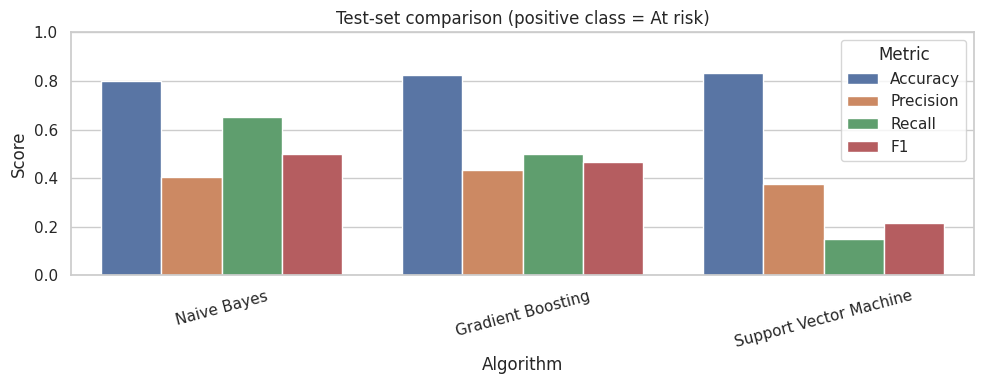

Confusion matrix for Naive Bayes
[[true pass, false at-risk], [missed at-risk, true at-risk]]
[[91 19]
 [ 7 13]]


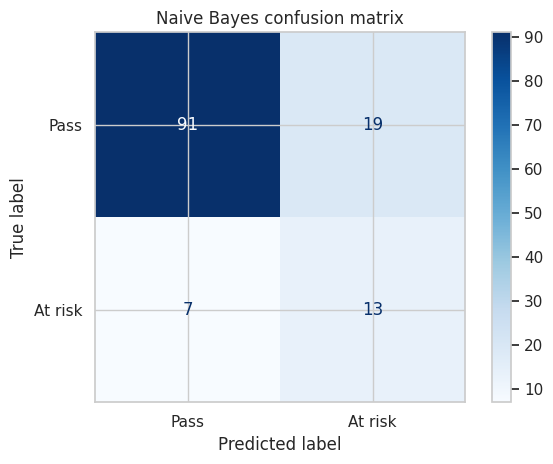


Why the winner wins
Naive Bayes has the highest F1 for AtRisk.
Do not choose by accuracy alone: most students pass, so accuracy can hide weak recall.
- Naive Bayes: accuracy=0.800, precision=0.406, recall=0.650, F1=0.500
- Gradient Boosting: accuracy=0.823, precision=0.435, recall=0.500, F1=0.465
- Support Vector Machine: accuracy=0.831, precision=0.375, recall=0.150, F1=0.214


In [7]:
rows = []
predictions = {}
for name, model in trained.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
    })

results = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
print("Comparison sorted by F1 of the at-risk class")
shown = results.copy()
for column in ["Accuracy", "Precision", "Recall", "F1"]:
    shown[column] = (shown[column] * 100).round(2).astype(str) + "%"
display(shown)

best_name = results.iloc[0]["Algorithm"]
print("\nDetailed report for the best model:", best_name)
print(classification_report(
    y_test, predictions[best_name],
    target_names=["Pass", "At risk"], digits=3
))

plot_df = results.melt(
    id_vars="Algorithm",
    value_vars=["Accuracy", "Precision", "Recall", "F1"],
    var_name="Metric",
    value_name="Score",
)
plt.figure(figsize=(10, 4))
sns.barplot(data=plot_df, x="Algorithm", y="Score", hue="Metric")
plt.ylim(0, 1)
plt.title("Test-set comparison (positive class = At risk)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_test, predictions[best_name])
print("Confusion matrix for", best_name)
print("[[true pass, false at-risk], [missed at-risk, true at-risk]]")
print(cm)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Pass", "At risk"]).plot(
    cmap="Blues", values_format="d"
)
plt.title(best_name + " confusion matrix")
plt.tight_layout()
plt.show()

print("\nWhy the winner wins")
print(best_name, "has the highest F1 for AtRisk.")
print("Do not choose by accuracy alone: most students pass, so accuracy can hide weak recall.")
for _, row in results.iterrows():
    print(
        f"- {row['Algorithm']}: accuracy={row['Accuracy']:.3f}, "
        f"precision={row['Precision']:.3f}, recall={row['Recall']:.3f}, F1={row['F1']:.3f}"
    )


## 7. Prediction and interpretation

We create three new students who are **not** copied from the CSV. The best model predicts whether each one is at risk and shows the probability.

| Example student | Story |
|---|---|
| Student A | Strong profile: wants higher education, educated parents, no past failures, few absences. |
| Student B | Mixed profile: one past failure, average study habits, some absences. |
| Student C | Weak profile: many past failures, little study time, many absences, no higher-education plan, low parent education. |

Interpretation rule: `AtRisk = 1` means the model expects a final grade below 10.


In [8]:
# Build three realistic example students using the most common category / median number
template = {}
for col in categorical_features:
    template[col] = X_train[col].mode().iloc[0]
for col in numeric_features:
    template[col] = float(X_train[col].median())

student_a = template.copy()
student_a.update({
    "higher": "yes", "failures": 0, "studytime": 3, "absences": 0,
    "schoolsup": "no", "internet": "yes", "goout": 2, "Walc": 1,
    "Medu": 4, "Fedu": 4, "age": 16,
})

student_b = template.copy()
student_b.update({
    "higher": "yes", "failures": 1, "studytime": 2, "absences": 8,
    "schoolsup": "yes", "internet": "yes", "goout": 3, "Walc": 3,
    "Medu": 2, "Fedu": 2, "age": 17,
})

student_c = template.copy()
student_c.update({
    "higher": "no", "failures": 3, "studytime": 1, "absences": 25,
    "schoolsup": "no", "famsup": "no", "internet": "no", "paid": "no",
    "goout": 5, "Dalc": 4, "Walc": 5, "Medu": 1, "Fedu": 1, "age": 19,
    "health": 2, "traveltime": 3,
})

examples = pd.DataFrame(
    [student_a, student_b, student_c],
    index=["Student A (strong)", "Student B (mixed)", "Student C (weak)"],
)

chosen = trained[best_name]
labels = chosen.predict(examples)
proba = chosen.predict_proba(examples)[:, 1]

report = examples[["failures", "studytime", "absences", "higher", "internet"]].copy()
report["Predicted"] = np.where(labels == 1, "At risk", "Pass")
report["P(at risk)"] = proba.round(3)

print("Model used for prediction:", best_name)
display(report)

print("\nInterpretation")
for name, pred, p in zip(report.index, report["Predicted"], report["P(at risk)"]):
    print(f"- {name}: predicted {pred} with estimated probability {p:.3f} of being at risk.")
print(
    "These probabilities are model estimates, not certainty. "
    "They are reasonable if the strong profile is low risk and the weak profile is high risk."
)
print("\nDone. Test students:", len(y_test), "| Best F1:", round(float(results.iloc[0]["F1"]), 4))


Model used for prediction: Naive Bayes


,failures,studytime,absences,higher,internet,Predicted,P(at risk)
Student A (strong),0,3,0,yes,yes,Pass,0.000
Student B (mixed),1,2,8,yes,yes,Pass,0.002
Student C (weak),3,1,25,no,no,At risk,1.000



Interpretation
- Student A (strong): predicted Pass with estimated probability 0.000 of being at risk.
- Student B (mixed): predicted Pass with estimated probability 0.002 of being at risk.
- Student C (weak): predicted At risk with estimated probability 1.000 of being at risk.
These probabilities are model estimates, not certainty. They are reasonable if the strong profile is low risk and the weak profile is high risk.

Done. Test students: 130 | Best F1: 0.5
